In [1]:
!pip -q install wandb

In [2]:
import os, math, copy, random, time, gc, json, platform
from dataclasses import dataclass
from collections import OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as T
from torchvision.models import mobilenet_v2

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| PyTorch:", torch.__version__, "| Torchvision:", torchvision.__version__)

Device: cuda | PyTorch: 2.14.1+cu130 | Torchvision: 0.29.1+cu130


In [3]:
# -------------------- Configuration --------------------
BATCH_SIZE = 128
EPOCHS = 20
NUM_WORKERS = 2
IMAGE_SIZE = 96
LEARNING_RATE = 0.05
WEIGHT_DECAY = 5e-4
LABEL_SMOOTHING = 0.05
SEED = 42

# Keep False for the first run. Set True after W&B authentication.
USE_WANDB = True
WANDB_PROJECT = "cs6886w-mobilenetv2-cifar10"

# CIFAR-10 channel statistics
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

# Re-apply seed after configuration is loaded
set_seed(SEED)

# -------------------- CIFAR-10 data --------------------
train_transform = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.ToTensor(),
    T.Normalize(CIFAR_MEAN, CIFAR_STD),
])

test_transform = T.Compose([
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.ToTensor(),
    T.Normalize(CIFAR_MEAN, CIFAR_STD),
])

train_set = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=train_transform
)
test_set = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=test_transform
)

train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)
test_loader = DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)

CLASS_NAMES = train_set.classes
print(f"Device: {DEVICE}")
print(f"Training images: {len(train_set)} | Test images: {len(test_set)}")
print(f"Training batches: {len(train_loader)} | Test batches: {len(test_loader)}")
print("Classes:", CLASS_NAMES)


100%|██████████| 170M/170M [23:07<00:00, 123kB/s]


Device: cuda
Training images: 50000 | Test images: 10000
Training batches: 391 | Test batches: 79
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [4]:
def build_model(num_classes=10, width_mult=1.0, dropout=0.2):
    # MobileNetV2 from torchvision; replace the ImageNet classifier for 10 CIFAR classes.
    model = mobilenet_v2(weights=None, width_mult=width_mult, dropout=dropout)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model

model = build_model().to(DEVICE)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
  

In [5]:
print("DEVICE:", DEVICE)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

!nvidia-smi

DEVICE: cuda
CUDA available: True
GPU: Tesla T4
Thu Nov 26 06:32:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P0             26W /   70W |     133MiB /  15360MiB |      5%      Default |
|                                         |                        |                  N/A |


In [6]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    total_loss, correct, total = 0.0, 0, 0

    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        logits = model(x)
        total_loss += criterion(logits, y).item() * y.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        total += y.size(0)

    if total == 0:
        raise ValueError("The evaluation DataLoader is empty.")

    return total_loss / total, 100.0 * correct / total


def train_model(
    model,
    train_loader,
    test_loader,
    epochs=None,
    lr=None,
    use_wandb=False,
):
    # Resolve defaults at call time, after configuration has been executed.
    epochs = EPOCHS if epochs is None else epochs
    lr = LEARNING_RATE if lr is None else lr

    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    optimizer = optim.SGD(
        model.parameters(),
        lr=lr,
        momentum=0.9,
        weight_decay=WEIGHT_DECAY,
        nesterov=True,
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {
        "train_loss": [], "train_acc": [],
        "test_loss": [], "test_acc": [], "lr": [],
    }

    amp_enabled = (DEVICE.type == "cuda")
    scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        start = time.time()

        for x, y in train_loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=amp_enabled):
                logits = model(x)
                loss = criterion(logits, y)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * y.size(0)
            correct += (logits.argmax(dim=1) == y).sum().item()
            total += y.size(0)

        scheduler.step()

        train_loss = running_loss / total
        train_acc = 100.0 * correct / total
        test_loss, test_acc = evaluate(model, test_loader)
        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)
        history["lr"].append(current_lr)

        if use_wandb:
            import wandb
            wandb.log({
                "epoch": epoch + 1,
                "train_loss": train_loss,
                "train_accuracy": train_acc,
                "test_loss": test_loss,
                "test_accuracy": test_acc,
                "learning_rate": current_lr,
            })

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"train loss {train_loss:.4f} acc {train_acc:.2f}% | "
            f"test loss {test_loss:.4f} acc {test_acc:.2f}% | "
            f"{time.time() - start:.1f}s"
        )

    return history


# -------------------- Baseline training --------------------
if USE_WANDB:
    import wandb
    wandb.login()
    wandb.init(
        project=WANDB_PROJECT,
        name="baseline",
        config={
            "model": "MobileNetV2",
            "dataset": "CIFAR10",
            "epochs": EPOCHS,
            "batch_size": BATCH_SIZE,
            "optimizer": "SGD",
            "lr": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "seed": SEED,
            "image_size": IMAGE_SIZE,
        },
    )

history = train_model(
    model,
    train_loader,
    test_loader,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    use_wandb=USE_WANDB,
)

if USE_WANDB:
    wandb.finish()

baseline_loss, baseline_acc = evaluate(model, test_loader)
print(f"Baseline test loss: {baseline_loss:.4f}")
print(f"Baseline test top-1 accuracy: {baseline_acc:.2f}%")

baseline_state = {
    key: value.detach().cpu().clone()
    for key, value in model.state_dict().items()
}


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: keerthana_cs25m512 (keerthana_cs25m512-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


/tmp/ipykernel_445/2529486352.py:50: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)
/tmp/ipykernel_445/2529486352.py:63: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=amp_enabled):


Epoch 01/20 | train loss 1.7809 acc 38.31% | test loss 1.3251 acc 52.34% | 52.4s
Epoch 02/20 | train loss 1.3404 acc 56.70% | test loss 1.0813 acc 62.30% | 46.1s
Epoch 03/20 | train loss 1.1330 acc 65.80% | test loss 0.8639 acc 70.54% | 46.9s
Epoch 04/20 | train loss 0.9975 acc 71.47% | test loss 0.8656 acc 71.03% | 48.9s
Epoch 05/20 | train loss 0.9019 acc 75.64% | test loss 0.7335 acc 75.17% | 47.5s
Epoch 06/20 | train loss 0.8364 acc 78.13% | test loss 0.6356 acc 79.15% | 50.6s
Epoch 07/20 | train loss 0.7903 acc 80.00% | test loss 0.6292 acc 79.29% | 50.5s
Epoch 08/20 | train loss 0.7547 acc 81.51% | test loss 0.6015 acc 80.81% | 50.9s
Epoch 09/20 | train loss 0.7184 acc 82.92% | test loss 0.5725 acc 81.42% | 51.3s
Epoch 10/20 | train loss 0.6895 acc 84.02% | test loss 0.5050 acc 83.86% | 52.3s
Epoch 11/20 | train loss 0.6585 acc 85.19% | test loss 0.4918 acc 84.36% | 50.9s
Epoch 12/20 | train loss 0.6277 acc 86.62% | test loss 0.4730 acc 84.88% | 52.2s
Epoch 13/20 | train loss 0.6

epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
learning_rate,███▇▇▇▆▆▅▅▄▃▃▂▂▂▁▁▁▁
test_accuracy,▁▃▄▄▅▆▆▆▆▇▇▇▇▇▇█████
test_loss,█▆▅▅▄▃▃▃▃▂▂▂▂▂▂▁▁▁▁▁
train_accuracy,▁▃▄▅▆▆▆▆▇▇▇▇▇▇██████
train_loss,█▆▅▄▃▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁
epoch,20
learning_rate,0
test_accuracy,89.97
test_loss,0.33609
train_accuracy,93.806


Baseline test loss: 0.3361
Baseline test top-1 accuracy: 89.97%


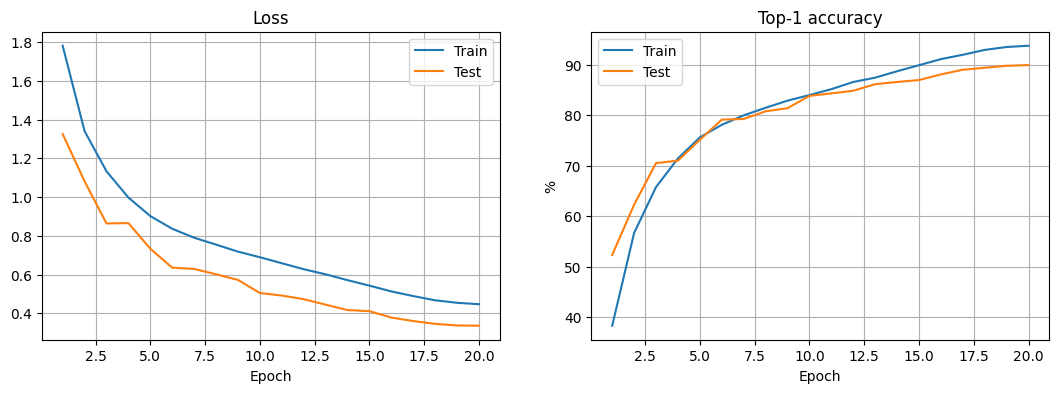

In [7]:
# Baseline curves
epochs_axis = np.arange(1, len(history["train_loss"])+1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(epochs_axis, history["train_loss"], label="Train")
ax[0].plot(epochs_axis, history["test_loss"], label="Test")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend(); ax[0].grid(True)
ax[1].plot(epochs_axis, history["train_acc"], label="Train")
ax[1].plot(epochs_axis, history["test_acc"], label="Test")
ax[1].set_title("Top-1 accuracy"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("%"); ax[1].legend(); ax[1].grid(True)
plt.show()

In [8]:
import sys, gc, math, time, copy
from collections import OrderedDict

# Reproducibility for compression experiments
set_seed(SEED)

# Configurations: at least 8, including conservative higher-bit settings
SWEEP_CONFIGS = [
    {"weight_bits": 8, "activation_bits": 8},
    {"weight_bits": 8, "activation_bits": 6},
    {"weight_bits": 6, "activation_bits": 8},
    {"weight_bits": 6, "activation_bits": 6},
    {"weight_bits": 6, "activation_bits": 4},
    {"weight_bits": 4, "activation_bits": 8},
    {"weight_bits": 4, "activation_bits": 6},
    {"weight_bits": 4, "activation_bits": 4},
]
RECOVERY_EPOCHS = 3
RECOVERY_LR = 0.001


In [9]:
def per_channel_symmetric_qdq(weight, bits):
    """Symmetric per-output-channel fake quantization; channel axis is 0."""
    if not 2 <= bits <= 8:
        raise ValueError("bits must be in [2, 8]")
    qmax = (1 << (bits - 1)) - 1
    reduce_dims = tuple(range(1, weight.ndim))
    max_abs = weight.detach().abs().amax(dim=reduce_dims, keepdim=True)
    scale = (max_abs / qmax).clamp_min(1e-8)
    q = torch.round(weight / scale).clamp(-qmax, qmax)
    return q * scale

def apply_weight_quantization_(model, bits):
    """Quantize Conv/Linear weights per output channel; keep bias FP32."""
    with torch.no_grad():
        for module in model.modules():
            if isinstance(module, (nn.Conv2d, nn.Linear)):
                module.weight.copy_(per_channel_symmetric_qdq(module.weight, bits))
    return model

class ReLU6ActivationFakeQuant:
    """Fixed-range unsigned fake quantization on ReLU6 outputs only."""
    def __init__(self, bits):
        self.bits = bits
        self.handles = []
        self.peak_numel = 0
        self.peak_shape = None
        self.peak_layer = None
    def _hook(self, name):
        def fn(module, inputs, output):
            if not torch.is_tensor(output):
                return output
            n = output.numel()
            if n > self.peak_numel:
                self.peak_numel, self.peak_shape, self.peak_layer = n, tuple(output.shape), name
            qmax = (1 << self.bits) - 1
            scale = 6.0 / qmax
            q = torch.round(output.clamp(0.0, 6.0) / scale).clamp(0, qmax)
            return q * scale
        return fn
    def attach(self, model):
        for name, module in model.named_modules():
            if isinstance(module, nn.ReLU6):
                self.handles.append(module.register_forward_hook(self._hook(name)))
        return self
    def remove(self):
        for h in self.handles: h.remove()
        self.handles.clear()

def make_recovery_model(baseline_state, weight_bits, activation_bits):
    m = build_model().to(DEVICE)
    m.load_state_dict(baseline_state)
    apply_weight_quantization_(m, weight_bits)
    aq = ReLU6ActivationFakeQuant(activation_bits).attach(m)
    return m, aq

@torch.no_grad()
def evaluate_with_memory(model, loader, aq=None, max_batches=None):
    model.eval()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats(DEVICE)
        allocated_before = torch.cuda.memory_allocated(DEVICE)
    else:
        allocated_before = 0
    total_loss, correct, total = 0.0, 0, 0
    for bi, (x, y) in enumerate(loader):
        if max_batches is not None and bi >= max_batches: break
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        loss = nn.functional.cross_entropy(logits, y)
        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)
        peak = torch.cuda.max_memory_allocated(DEVICE)
        inference_peak_delta = max(0, peak - allocated_before)
    else:
        peak, inference_peak_delta = 0, 0
    return total_loss/total, 100.0*correct/total, int(peak), int(inference_peak_delta)

def recovery_finetune(model, train_loader, epochs=RECOVERY_EPOCHS, lr=RECOVERY_LR):
    """Short recovery fine-tuning with activation fake quantization enabled."""
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()
    for ep in range(epochs):
        model.train(); running=0.0; seen=0
        for x,y in train_loader:
            x,y=x.to(DEVICE, non_blocking=True),y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits=model(x); loss=criterion(logits,y)
            loss.backward(); optimizer.step()
            running += loss.item()*y.size(0); seen += y.size(0)
        print(f"  recovery epoch {ep+1}/{epochs}: loss={running/seen:.4f}")
    return model


In [10]:
def pack_unsigned_codes(q, bits):
    """Pack unsigned integer codes into a real uint8 bitstream (little-endian bits)."""
    arr = q.detach().to("cpu", dtype=torch.int64).reshape(-1).numpy()
    arr = np.clip(arr, 0, (1 << bits)-1).astype(np.uint32)
    out = np.zeros((arr.size*bits + 7)//8, dtype=np.uint8)
    bitpos = np.arange(arr.size, dtype=np.int64) * bits
    for b in range(bits):
        pos = bitpos + b
        np.bitwise_or.at(out, pos//8, (((arr >> b) & 1).astype(np.uint8)) << (pos%8).astype(np.uint8))
    return out.tobytes()

def build_resident_packed_weight_store(state, bits):
    """Build actual in-memory packed byte buffers + per-output-channel scales.
    Biases and BatchNorm/buffers remain FP32 and are counted as raw bytes.
    """
    packed = {}
    raw_bytes = 0
    scale_bytes = 0
    for name, tensor in state.items():
        is_quant_weight = (name.endswith('.weight') and tensor.ndim >= 2 and
                           (name.startswith('features.') or name.startswith('classifier.')))
        if is_quant_weight:
            qmax = (1 << (bits-1))-1
            dims = tuple(range(1, tensor.ndim))
            max_abs = tensor.abs().amax(dim=dims, keepdim=True)
            scales = (max_abs/qmax).clamp_min(1e-8)
            q = torch.round(tensor/scales).clamp(-qmax,qmax).to(torch.int16)
            # Offset signed codes into [0, 2^bits-1] for packing.
            codes = q + (1 << (bits-1))
            payload = pack_unsigned_codes(codes, bits)
            scale_array = scales.reshape(-1).cpu().numpy().astype(np.float32)
            packed[name] = {"payload": payload, "shape": tuple(tensor.shape),
                            "scales": scale_array.tobytes(), "bits": bits}
            scale_bytes += len(scale_array.tobytes())
        else:
            raw_bytes += tensor.numel() * tensor.element_size()
    payload_bytes = sum(len(v["payload"]) for v in packed.values())
    # Include explicit small per-tensor shape/bit-width descriptor allowance.
    descriptor_bytes = sum(16 + 4*len(v["shape"]) for v in packed.values())
    total_resident_bytes = payload_bytes + scale_bytes + descriptor_bytes + raw_bytes
    return packed, {"packed_payload_bytes":payload_bytes, "scale_bytes":scale_bytes,
                    "descriptor_bytes":descriptor_bytes, "uncompressed_tensor_bytes":raw_bytes,
                    "total_resident_bytes":total_resident_bytes}

def run_improved_sweep():
    rows=[]
    for run,cfg in enumerate(SWEEP_CONFIGS,1):
        wb,ab=cfg['weight_bits'],cfg['activation_bits']
        print(f"\nRun {run}/{len(SWEEP_CONFIGS)}: W{wb}A{ab}")
        model_q, aq = make_recovery_model(baseline_state, wb, ab)
        recovery_finetune(model_q, train_loader, epochs=RECOVERY_EPOCHS, lr=RECOVERY_LR)
        # Re-apply weight quantization after recovery; activation fake quant remains attached.
        aq.remove()
        apply_weight_quantization_(model_q, wb)
        aq = ReLU6ActivationFakeQuant(ab).attach(model_q)
        loss,acc,peak_gpu,delta_gpu=evaluate_with_memory(model_q,test_loader,aq)
        peak_activation_bytes = math.ceil(aq.peak_numel*ab/8)
        fp32_peak_activation_bytes = aq.peak_numel*4
        packed_store, storage = build_resident_packed_weight_store(
            {k:v.detach().cpu() for k,v in model_q.state_dict().items()}, wb)
        rows.append({
            'run':run,'weight_bits':wb,'activation_bits':ab,
            'test_accuracy':acc,'test_loss':loss,
            'packed_weight_payload_MB':storage['packed_payload_bytes']/1e6,
            'scale_metadata_MB':(storage['scale_bytes']+storage['descriptor_bytes'])/1e6,
            'untouched_FP32_MB':storage['uncompressed_tensor_bytes']/1e6,
            'resident_packed_model_MB':storage['total_resident_bytes']/1e6,
            'baseline_state_MB':sum(v.numel()*v.element_size() for v in baseline_state.values())/1e6,
            'resident_weight_compression_ratio':(sum(v.numel()*v.element_size() for v in baseline_state.values())/storage['total_resident_bytes']),
            'largest_relu6_layer':aq.peak_layer,'largest_relu6_shape':str(aq.peak_shape),
            'activation_tensor_FP32_MB':fp32_peak_activation_bytes/1e6,
            'activation_packed_estimate_MB':peak_activation_bytes/1e6,
            'activation_tensor_ratio':fp32_peak_activation_bytes/max(1,peak_activation_bytes),
            'GPU_peak_allocated_MB':peak_gpu/1e6,
            'GPU_inference_peak_delta_MB':delta_gpu/1e6,
        })
        aq.remove(); del model_q, packed_store; gc.collect()
        if DEVICE.type=='cuda': torch.cuda.empty_cache()
    return pd.DataFrame(rows)

results_df = run_improved_sweep()
display(results_df.round(4))



Run 1/8: W8A8
  recovery epoch 1/3: loss=0.2148
  recovery epoch 2/3: loss=0.2067
  recovery epoch 3/3: loss=0.2008

Run 2/8: W8A6
  recovery epoch 1/3: loss=0.2428
  recovery epoch 2/3: loss=0.2334
  recovery epoch 3/3: loss=0.2266

Run 3/8: W6A8
  recovery epoch 1/3: loss=0.2176
  recovery epoch 2/3: loss=0.2070
  recovery epoch 3/3: loss=0.2013

Run 4/8: W6A6
  recovery epoch 1/3: loss=0.2442
  recovery epoch 2/3: loss=0.2354
  recovery epoch 3/3: loss=0.2291

Run 5/8: W6A4
  recovery epoch 1/3: loss=0.7716
  recovery epoch 2/3: loss=0.7638
  recovery epoch 3/3: loss=0.7621

Run 6/8: W4A8
  recovery epoch 1/3: loss=0.2384
  recovery epoch 2/3: loss=0.2313
  recovery epoch 3/3: loss=0.2236

Run 7/8: W4A6
  recovery epoch 1/3: loss=0.2670
  recovery epoch 2/3: loss=0.2583
  recovery epoch 3/3: loss=0.2497

Run 8/8: W4A4
  recovery epoch 1/3: loss=0.8081
  recovery epoch 2/3: loss=0.8118
  recovery epoch 3/3: loss=0.8067


,run,weight_bits,activation_bits,test_accuracy,test_loss,packed_weight_payload_MB,scale_metadata_MB,untouched_FP32_MB,resident_packed_model_MB,baseline_state_MB,resident_weight_compression_ratio,largest_relu6_layer,largest_relu6_shape,activation_tensor_FP32_MB,activation_packed_estimate_MB,activation_tensor_ratio,GPU_peak_allocated_MB,GPU_inference_peak_delta_MB
0,1,8,8,89.76,0.3271,2.2026,0.07,0.2734,2.5459,9.0836,3.5680,features.2.conv.0.2,"(128, 96, 48, 48)",113.2462,28.3116,4.0000,426.5395,372.7754
1,2,8,6,89.16,0.3428,2.2026,0.07,0.2734,2.5459,9.0836,3.5680,features.2.conv.0.2,"(128, 96, 48, 48)",113.2462,21.2337,5.3333,426.6051,372.7754
2,3,6,8,89.82,0.3273,1.6519,0.07,0.2734,1.9952,9.0836,4.5527,features.2.conv.0.2,"(128, 96, 48, 48)",113.2462,28.3116,4.0000,426.6051,372.7754
3,4,6,6,88.87,0.3447,1.6519,0.07,0.2734,1.9952,9.0836,4.5527,features.2.conv.0.2,"(128, 96, 48, 48)",113.2462,21.2337,5.3333,426.6051,372.7754
4,5,6,4,74.44,0.7794,1.6519,0.07,0.2734,1.9952,9.0836,4.5527,features.2.conv.0.2,"(128, 96, 48, 48)",113.2462,14.1558,8.0000,426.6051,372.7754
5,6,4,8,89.18,0.3451,1.1013,0.07,0.2734,1.4446,9.0836,6.2880,features.2.conv.0.2,"(128, 96, 48, 48)",113.2462,28.3116,4.0000,426.6051,372.7754
6,7,4,6,88.60,0.3668,1.1013,0.07,0.2734,1.4446,9.0836,6.2880,features.2.conv.0.2,"(128, 96, 48, 48)",113.2462,21.2337,5.3333,426.6051,372.7754
7,8,4,4,72.54,0.8429,1.1013,0.07,0.2734,1.4446,9.0836,6.2880,features.2.conv.0.2,"(128, 96, 48, 48)",113.2462,14.1558,8.0000,426.6051,372.7754


In [11]:
import wandb
import numpy as np

wandb.login()

# One W&B run for each compression configuration
for _, row in results_df.iterrows():

    weight_bits = int(row["weight_bits"])
    activation_bits = int(row["activation_bits"])

    run_name = f"weights-{weight_bits}bit_activations-{activation_bits}bit"

    config = {
        "weight_bits": weight_bits,
        "activation_bits": activation_bits,
        "seed": int(SEED),
        "dataset": "CIFAR-10",
        "model": "MobileNetV2",
        "baseline_accuracy": float(baseline_acc),
    }

    with wandb.init(
        project=WANDB_PROJECT,
        entity="keerthana_cs25m512-indian-institute-of-technology-madras",
        name=run_name,
        group="compression-sweep",
        job_type="compression",
        config=config,
        reinit=True,
    ) as run:

        # Log numeric results from this configuration
        metrics = {}

        for key, value in row.to_dict().items():
            if isinstance(value, (int, float, np.number)):
                metrics[key] = float(value)

        run.log(metrics)

        run.summary["test_accuracy"] = float(row["test_accuracy"])
        run.summary["test_loss"] = float(row["test_loss"])
        run.summary["resident_weight_compression_ratio"] = float(
            row["resident_weight_compression_ratio"]
        )
        run.summary["activation_tensor_ratio"] = float(
            row["activation_tensor_ratio"]
        )
        run.summary["resident_packed_model_MB"] = float(
            row["resident_packed_model_MB"]
        )

print("Logged all 8 compression configurations as separate W&B runs.")

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


GPU_inference_peak_delta_MB,▁
GPU_peak_allocated_MB,▁
activation_bits,▁
activation_packed_estimate_MB,▁
activation_tensor_FP32_MB,▁
activation_tensor_ratio,▁
baseline_state_MB,▁
packed_weight_payload_MB,▁
resident_packed_model_MB,▁
resident_weight_compression_ratio,▁
+6,...


GPU_inference_peak_delta_MB,▁
GPU_peak_allocated_MB,▁
activation_bits,▁
activation_packed_estimate_MB,▁
activation_tensor_FP32_MB,▁
activation_tensor_ratio,▁
baseline_state_MB,▁
packed_weight_payload_MB,▁
resident_packed_model_MB,▁
resident_weight_compression_ratio,▁
+6,...


GPU_inference_peak_delta_MB,▁
GPU_peak_allocated_MB,▁
activation_bits,▁
activation_packed_estimate_MB,▁
activation_tensor_FP32_MB,▁
activation_tensor_ratio,▁
baseline_state_MB,▁
packed_weight_payload_MB,▁
resident_packed_model_MB,▁
resident_weight_compression_ratio,▁
+6,...


GPU_inference_peak_delta_MB,▁
GPU_peak_allocated_MB,▁
activation_bits,▁
activation_packed_estimate_MB,▁
activation_tensor_FP32_MB,▁
activation_tensor_ratio,▁
baseline_state_MB,▁
packed_weight_payload_MB,▁
resident_packed_model_MB,▁
resident_weight_compression_ratio,▁
+6,...


GPU_inference_peak_delta_MB,▁
GPU_peak_allocated_MB,▁
activation_bits,▁
activation_packed_estimate_MB,▁
activation_tensor_FP32_MB,▁
activation_tensor_ratio,▁
baseline_state_MB,▁
packed_weight_payload_MB,▁
resident_packed_model_MB,▁
resident_weight_compression_ratio,▁
+6,...


wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


GPU_inference_peak_delta_MB,▁
GPU_peak_allocated_MB,▁
activation_bits,▁
activation_packed_estimate_MB,▁
activation_tensor_FP32_MB,▁
activation_tensor_ratio,▁
baseline_state_MB,▁
packed_weight_payload_MB,▁
resident_packed_model_MB,▁
resident_weight_compression_ratio,▁
+6,...


GPU_inference_peak_delta_MB,▁
GPU_peak_allocated_MB,▁
activation_bits,▁
activation_packed_estimate_MB,▁
activation_tensor_FP32_MB,▁
activation_tensor_ratio,▁
baseline_state_MB,▁
packed_weight_payload_MB,▁
resident_packed_model_MB,▁
resident_weight_compression_ratio,▁
+6,...


GPU_inference_peak_delta_MB,▁
GPU_peak_allocated_MB,▁
activation_bits,▁
activation_packed_estimate_MB,▁
activation_tensor_FP32_MB,▁
activation_tensor_ratio,▁
baseline_state_MB,▁
packed_weight_payload_MB,▁
resident_packed_model_MB,▁
resident_weight_compression_ratio,▁
+6,...


Logged all 8 compression configurations as separate W&B runs.


In [12]:
from pandas.plotting import parallel_coordinates

Baseline accuracy: 89.97%
Selected configuration:


,value
run,6
weight_bits,4
activation_bits,8
test_accuracy,89.18
test_loss,0.345074
packed_weight_payload_MB,1.10128
scale_metadata_MB,0.069952
untouched_FP32_MB,0.273352
resident_packed_model_MB,1.444584
baseline_state_MB,9.083592


,run,weight_bits,activation_bits,packed_weight_payload_MB,scale_metadata_MB,untouched_FP32_MB,resident_packed_model_MB,resident_weight_compression_ratio,activation_tensor_FP32_MB,activation_packed_estimate_MB,activation_tensor_ratio,GPU_peak_allocated_MB,GPU_inference_peak_delta_MB,test_accuracy
0,1,8,8,2.2026,0.07,0.2734,2.5459,3.5680,113.2462,28.3116,4.0000,426.5395,372.7754,89.76
1,2,8,6,2.2026,0.07,0.2734,2.5459,3.5680,113.2462,21.2337,5.3333,426.6051,372.7754,89.16
2,3,6,8,1.6519,0.07,0.2734,1.9952,4.5527,113.2462,28.3116,4.0000,426.6051,372.7754,89.82
3,4,6,6,1.6519,0.07,0.2734,1.9952,4.5527,113.2462,21.2337,5.3333,426.6051,372.7754,88.87
4,5,6,4,1.6519,0.07,0.2734,1.9952,4.5527,113.2462,14.1558,8.0000,426.6051,372.7754,74.44
5,6,4,8,1.1013,0.07,0.2734,1.4446,6.2880,113.2462,28.3116,4.0000,426.6051,372.7754,89.18
6,7,4,6,1.1013,0.07,0.2734,1.4446,6.2880,113.2462,21.2337,5.3333,426.6051,372.7754,88.60
7,8,4,4,1.1013,0.07,0.2734,1.4446,6.2880,113.2462,14.1558,8.0000,426.6051,372.7754,72.54


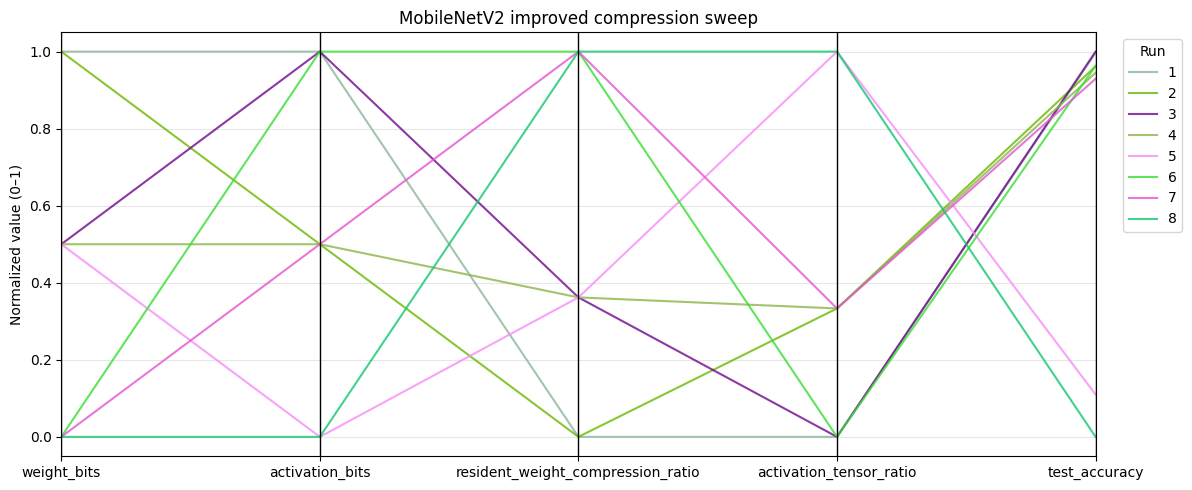

In [13]:
# Select best accuracy first; among configurations within 2 percentage points of baseline,
# prefer the highest resident packed-model compression ratio.
eligible = results_df[results_df.test_accuracy >= baseline_acc - 2.0]
if len(eligible):
    best_row = eligible.sort_values(
        ['resident_weight_compression_ratio','test_accuracy'], ascending=[False,False]
    ).iloc[0]
else:
    best_row = results_df.sort_values(
        ['test_accuracy','resident_weight_compression_ratio'], ascending=[False,False]
    ).iloc[0]

print(f"Baseline accuracy: {baseline_acc:.2f}%")
print("Selected configuration:")
display(best_row.to_frame('value'))

# Accounting table required for the report
accounting = results_df[[
    'run','weight_bits','activation_bits','packed_weight_payload_MB',
    'scale_metadata_MB','untouched_FP32_MB','resident_packed_model_MB',
    'resident_weight_compression_ratio','activation_tensor_FP32_MB',
    'activation_packed_estimate_MB','activation_tensor_ratio',
    'GPU_peak_allocated_MB','GPU_inference_peak_delta_MB','test_accuracy'
]].copy()
display(accounting.round(4))

# Parallel-coordinates figure. W&B logging below can be enabled for the required W&B panel.
plot_cols=['weight_bits','activation_bits','resident_weight_compression_ratio',
           'activation_tensor_ratio','test_accuracy']
plot_df=results_df[plot_cols].copy()
for c in plot_df.columns:
    lo,hi=plot_df[c].min(),plot_df[c].max()
    plot_df[c]=(plot_df[c]-lo)/(hi-lo) if hi>lo else 0.5
plot_df['run']=results_df['run'].astype(str)
plt.figure(figsize=(12,5))
parallel_coordinates(plot_df,'run',alpha=0.8)
plt.title('MobileNetV2 improved compression sweep')
plt.ylabel('Normalized value (0–1)'); plt.grid(True,alpha=.3)
plt.legend(title='Run',bbox_to_anchor=(1.02,1),loc='upper left')
plt.tight_layout(); plt.show()


In [14]:
import shutil
import os
import json
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt

In [15]:
# Export all reproducibility artifacts
OUTPUT_DIR='assignment2_outputs_improved'
os.makedirs(OUTPUT_DIR,exist_ok=True)
results_df.to_csv(os.path.join(OUTPUT_DIR,'compression_sweep_results.csv'),index=False)
accounting.to_csv(os.path.join(OUTPUT_DIR,'compression_accounting.csv'),index=False)
torch.save(baseline_state,os.path.join(OUTPUT_DIR,'mobilenetv2_cifar10_baseline_state.pth'))

summary={
 'seed':int(SEED),'device':str(DEVICE),'torch_version':torch.__version__,
 'torchvision_version':torchvision.__version__,'epochs_baseline':int(EPOCHS),
 'recovery_epochs_per_configuration':int(RECOVERY_EPOCHS),
 'recovery_learning_rate':float(RECOVERY_LR),'batch_size':int(BATCH_SIZE),
 'image_size':int(IMAGE_SIZE),'baseline_test_accuracy':float(baseline_acc),
 'baseline_test_loss':float(baseline_loss),'number_of_compression_runs':int(len(results_df)),
 'selected_configuration':{k:(v.item() if isinstance(v,np.generic) else v) for k,v in best_row.to_dict().items()},
 'memory_note':'Packed model bytes are measured as resident CPU byte buffers plus scales/descriptors and untouched FP32 tensors. GPU peak allocation is measured separately. This notebook uses fake-quantized FP32 execution; it does not claim native low-bit GPU kernels or reduced GPU weight residency.'
}
with open(os.path.join(OUTPUT_DIR,'metrics_summary.json'),'w') as f: json.dump(summary,f,indent=2,default=str)

# Baseline training curves
fig,ax=plt.subplots(1,2,figsize=(13,4)); ep=np.arange(1,len(history['train_loss'])+1)
ax[0].plot(ep,history['train_loss'],label='Train'); ax[0].plot(ep,history['test_loss'],label='Test')
ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend(); ax[0].grid(True)
ax[1].plot(ep,history['train_acc'],label='Train'); ax[1].plot(ep,history['test_acc'],label='Test')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('%'); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR,'baseline_training_curves.png'),dpi=250); plt.close()

# Save compression parallel-coordinates plot
plt.figure(figsize=(12,5)); parallel_coordinates(plot_df,'run',alpha=.8)
plt.title('MobileNetV2 improved compression sweep'); plt.ylabel('Normalized value (0–1)')
plt.grid(True,alpha=.3); plt.legend(title='Run',bbox_to_anchor=(1.02,1),loc='upper left')
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR,'compression_parallel_coordinates.png'),dpi=250,bbox_inches='tight'); plt.close()

with open(os.path.join(OUTPUT_DIR,'results_report.txt'),'w') as f:
    f.write('CS6886W ASSIGNMENT 2 - IMPROVED COMPRESSION RESULTS\n')
    f.write(f'Baseline accuracy: {baseline_acc:.2f}%\nBaseline loss: {baseline_loss:.4f}\n')
    f.write(f'Runs: {len(results_df)}\n\nSelected configuration:\n{best_row.to_string()}\n\n')
    f.write(results_df.to_string(index=False))

zip_path=shutil.make_archive(OUTPUT_DIR,'zip',root_dir='.',base_dir=OUTPUT_DIR)
print('Saved:',zip_path)
for fn in sorted(os.listdir(OUTPUT_DIR)): print(' -',fn)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print('Not running in Colab; download the ZIP from the file browser.')


Saved: /content/assignment2_outputs_improved.zip
 - baseline_training_curves.png
 - compression_accounting.csv
 - compression_parallel_coordinates.png
 - compression_sweep_results.csv
 - metrics_summary.json
 - mobilenetv2_cifar10_baseline_state.pth
 - results_report.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
%pip install -U wandb wandb-workspaces

In [4]:
import wandb
import wandb_workspaces.reports.v2 as wr

wandb.login()

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /root/.netrc.
wandb: Currently logged in as: keerthana_cs25m512 (keerthana_cs25m512-indian-institute-of-technology-madras) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


True

In [12]:
import os
import glob
import pandas as pd

# Find the compression results CSV in the Colab workspace
csv_files = glob.glob(
    "/content/**/compression_sweep_results.csv",
    recursive=True
)

print("CSV files found:")
for f in csv_files:
    print(f)


CSV files found:
/content/assignment2_outputs_improved/compression_sweep_results.csv


In [13]:
# Use the path printed by the previous cell
csv_path = csv_files[0]

results_df = pd.read_csv(csv_path)

print("Results loaded:", results_df.shape)
display(results_df)
print("Columns:", results_df.columns.tolist())


Results loaded: (8, 18)


,run,weight_bits,activation_bits,test_accuracy,test_loss,packed_weight_payload_MB,scale_metadata_MB,untouched_FP32_MB,resident_packed_model_MB,baseline_state_MB,resident_weight_compression_ratio,largest_relu6_layer,largest_relu6_shape,activation_tensor_FP32_MB,activation_packed_estimate_MB,activation_tensor_ratio,GPU_peak_allocated_MB,GPU_inference_peak_delta_MB
0,1,8,8,89.76,0.327130,2.20256,0.069952,0.273352,2.545864,9.083592,3.567980,features.2.conv.0.2,"(128, 96, 48, 48)",113.246208,28.311552,4.000000,426.539520,372.775424
1,2,8,6,89.16,0.342824,2.20256,0.069952,0.273352,2.545864,9.083592,3.567980,features.2.conv.0.2,"(128, 96, 48, 48)",113.246208,21.233664,5.333333,426.605056,372.775424
2,3,6,8,89.82,0.327313,1.65192,0.069952,0.273352,1.995224,9.083592,4.552668,features.2.conv.0.2,"(128, 96, 48, 48)",113.246208,28.311552,4.000000,426.605056,372.775424
3,4,6,6,88.87,0.344673,1.65192,0.069952,0.273352,1.995224,9.083592,4.552668,features.2.conv.0.2,"(128, 96, 48, 48)",113.246208,21.233664,5.333333,426.605056,372.775424
4,5,6,4,74.44,0.779404,1.65192,0.069952,0.273352,1.995224,9.083592,4.552668,features.2.conv.0.2,"(128, 96, 48, 48)",113.246208,14.155776,8.000000,426.605056,372.775424
5,6,4,8,89.18,0.345074,1.10128,0.069952,0.273352,1.444584,9.083592,6.288033,features.2.conv.0.2,"(128, 96, 48, 48)",113.246208,28.311552,4.000000,426.605056,372.775424
6,7,4,6,88.60,0.366808,1.10128,0.069952,0.273352,1.444584,9.083592,6.288033,features.2.conv.0.2,"(128, 96, 48, 48)",113.246208,21.233664,5.333333,426.605056,372.775424
7,8,4,4,72.54,0.842858,1.10128,0.069952,0.273352,1.444584,9.083592,6.288033,features.2.conv.0.2,"(128, 96, 48, 48)",113.246208,14.155776,8.000000,426.605056,372.775424


Columns: ['run', 'weight_bits', 'activation_bits', 'test_accuracy', 'test_loss', 'packed_weight_payload_MB', 'scale_metadata_MB', 'untouched_FP32_MB', 'resident_packed_model_MB', 'baseline_state_MB', 'resident_weight_compression_ratio', 'largest_relu6_layer', 'largest_relu6_shape', 'activation_tensor_FP32_MB', 'activation_packed_estimate_MB', 'activation_tensor_ratio', 'GPU_peak_allocated_MB', 'GPU_inference_peak_delta_MB']


In [14]:
# W&B Parallel Coordinates Plot - no report-editing API

import wandb
import plotly.graph_objects as go
import pandas as pd

# If results_df is not currently in memory, load your results CSV first.
# Example:
# results_df = pd.read_csv("assignment2_outputs_improved/compression_sweep_results.csv")

# Confirm required columns exist
required_cols = [
    "weight_bits",
    "activation_bits",
    "test_accuracy",
    "resident_weight_compression_ratio",
    "activation_tensor_ratio",
    "resident_packed_model_MB",
]

missing = [c for c in required_cols if c not in results_df.columns]
if missing:
    raise ValueError(
        f"Missing columns in results_df: {missing}\n"
        f"Available columns: {list(results_df.columns)}"
    )

# Keep only the 8 configurations and required columns
plot_df = results_df[required_cols].copy()
plot_df = plot_df.dropna()

# Build parallel coordinates dimensions
dimensions = [
    dict(
        label="Weight Bits",
        values=plot_df["weight_bits"],
        range=[plot_df["weight_bits"].min(), plot_df["weight_bits"].max()],
        tickvals=[4, 6, 8],
    ),
    dict(
        label="Activation Bits",
        values=plot_df["activation_bits"],
        range=[plot_df["activation_bits"].min(), plot_df["activation_bits"].max()],
        tickvals=[4, 6, 8],
    ),
    dict(
        label="Test Accuracy (%)",
        values=plot_df["test_accuracy"],
    ),
    dict(
        label="Weight Compression Ratio",
        values=plot_df["resident_weight_compression_ratio"],
    ),
    dict(
        label="Activation Tensor Ratio",
        values=plot_df["activation_tensor_ratio"],
    ),
    dict(
        label="Resident Model Size (MB)",
        values=plot_df["resident_packed_model_MB"],
    ),
]

# Create interactive parallel coordinates plot
fig = go.Figure(
    data=go.Parcoords(
        line=dict(
            color=plot_df["test_accuracy"],
            colorscale="Viridis",
            showscale=True,
            colorbar=dict(title="Accuracy"),
        ),
        dimensions=dimensions,
    )
)

fig.update_layout(
    title="MobileNetV2 Compression - Parallel Coordinates",
    width=1200,
    height=650,
)

# Display in notebook
fig.show()

# Save interactive HTML locally
html_path = "compression_parallel_coordinates.html"
fig.write_html(html_path)

# Log the interactive chart to W&B
wandb.login()

with wandb.init(
    entity="keerthana_cs25m512-indian-institute-of-technology-madras",
    project="cs6886w-mobilenetv2-cifar10",
    name="compression-parallel-coordinates-chart",
    job_type="visualization",
    reinit=True,
) as run:
    run.log({
        "parallel_coordinates_plot": wandb.Html(fig.to_html())
    })

    run.summary["number_of_compression_configs"] = len(plot_df)

print("Parallel Coordinates chart created and logged to W&B.")
print("Saved local interactive chart:", html_path)

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


number_of_compression_configs,8


Parallel Coordinates chart created and logged to W&B.
Saved local interactive chart: compression_parallel_coordinates.html
